# Modelo 2 — Classificação de Risco de Falha por Janela Temporal (7 dias)

## 1. Contexto e Objetivo

O objetivo dessa análise é realizar a modelagem preditiva para a realização de manutenções das Portas de Plataforma (PSD).

**Tarefa definida:** classificação binária — para cada porta, em cada dia, prever se haverá uma falha nos próximos 7 dias.

**Dataset de entrada:** `dataset_modelo_final.csv`, construído em `construir_dataset_modelo.py` e
`preparar_features_modelo.py` a partir das bases já limpas em `data/` (Alarmes, ZM01, ZM02, ZM03,
Catracas).

Antes de escolher e ajustar um modelo final, é necessário medir o **peso de cada feature** na previsão de falha — via importância de um modelo baseline (Random Forest) e via importância por permutação (mais robusta a viés de features de alta cardinalidade). Isso orienta
quais features vale a pena manter, remover ou aprofundar antes do tuning.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay,
    precision_score, recall_score, accuracy_score, f1_score, precision_recall_curve,
)
import lightgbm as lgb

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', 40)

RANDOM_STATE = 42


## 2. Carregamento do dataset

In [2]:
df = pd.read_csv("dataset_modelo_final.csv", parse_dates=["data"])
print(f"Dimensao: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"Periodo: {df['data'].min().date()} a {df['data'].max().date()}")
print(f"Taxa de positivos (falha_7d=1): {df['falha_7d'].mean():.2%}")
df.head(3)


Dimensao: 296,472 linhas x 27 colunas
Periodo: 2023-02-27 a 2026-03-25
Taxa de positivos (falha_7d=1): 15.42%


,data,estacao,porta,falha_7d,estacao_BUT,estacao_FAL,estacao_FRA,estacao_FRE,estacao_HIG,estacao_LUZ,estacao_MBI,estacao_PIN,estacao_PTA,estacao_REP,estacao_VSO,n_alarmes_3d,n_alarmes_7d,n_alarmes_14d,n_alarmes_obs_7d,tempo_medio_normalizacao_7d,dias_desde_ultimo_alarme,passageiros_entrada,passageiros_saida,passageiros_media_7d,dias_desde_ultima_corretiva,dias_desde_ultima_preventiva,n_corretivas_90d
0,2023-02-27,BUT,1,1,True,False,False,False,False,False,False,False,False,False,False,0.0,0.0,0.0,0.0,NaN,NaN,32077.0,28915.0,NaN,NaN,NaN,0.0
1,2023-02-28,BUT,1,1,True,False,False,False,False,False,False,False,False,False,False,0.0,0.0,0.0,0.0,NaN,NaN,33202.0,29350.0,32077.0,NaN,NaN,0.0
2,2023-03-01,BUT,1,1,True,False,False,False,False,False,False,False,False,False,False,0.0,0.0,0.0,0.0,NaN,NaN,33410.0,29491.0,32639.5,NaN,NaN,0.0


## 3. Separação treino/teste

Como o objetivo é prever o **futuro**, o split não pode ser aleatório: um split aleatório misturaria dias de teste anteriores a dias de treino, vazando informação futura para o modelo (data leakage).
Em vez disso, ordenamos por data e reservamos os últimos ~20% dos dias como teste — simulando a situação real de prever falhas em dias que o modelo nunca viu.


In [3]:
df = df.sort_values("data").reset_index(drop=True)

datas_unicas = df["data"].sort_values().unique()
corte_idx = int(len(datas_unicas) * 0.8)
data_corte = datas_unicas[corte_idx]

treino = df[df["data"] < data_corte].copy()
teste = df[df["data"] >= data_corte].copy()

print(f"Data de corte: {pd.Timestamp(data_corte).date()}")
print(f"Treino: {len(treino):,} linhas ({treino['data'].min().date()} a {treino['data'].max().date()}), "
      f"positivos={treino['falha_7d'].mean():.2%}")
print(f"Teste:  {len(teste):,} linhas ({teste['data'].min().date()} a {teste['data'].max().date()}), "
      f"positivos={teste['falha_7d'].mean():.2%}")


Data de corte: 2025-08-13
Treino: 237,072 linhas (2023-02-27 a 2025-08-12), positivos=15.14%
Teste:  59,400 linhas (2025-08-13 a 2026-03-25), positivos=16.53%


## 4. Modelo baseline para medir peso das features

Random Forest é usado aqui como **baseline exploratório**, não como modelo final, ele serve para estimar a importância relativa de cada feature antes de decidir o algoritmo definitivo e fazer tuning de hiperparâmetros. `class_weight="balanced"` compensa o desbalanceamento (15,4% de positivos) sem precisar de oversampling nesta etapa exploratória.

Os dados de `data`, `estacao` e `porta` ficam de fora das features de entrada: são identificadores, não sinais preditivos, a informação de estação já está codificada via one-hot (`estacao_*`) e o histórico de cada porta já está capturado nas features de contagem/tempo.


In [4]:
colunas_excluidas = ["data", "estacao", "porta", "falha_7d"]
features = [c for c in df.columns if c not in colunas_excluidas]

X_treino, y_treino = treino[features], treino["falha_7d"]
X_teste, y_teste = teste[features], teste["falha_7d"]

modelo_base = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
modelo_base.fit(X_treino, y_treino)
print(f"{len(features)} features utilizadas:")
print(features)


23 features utilizadas:
['estacao_BUT', 'estacao_FAL', 'estacao_FRA', 'estacao_FRE', 'estacao_HIG', 'estacao_LUZ', 'estacao_MBI', 'estacao_PIN', 'estacao_PTA', 'estacao_REP', 'estacao_VSO', 'n_alarmes_3d', 'n_alarmes_7d', 'n_alarmes_14d', 'n_alarmes_obs_7d', 'tempo_medio_normalizacao_7d', 'dias_desde_ultimo_alarme', 'passageiros_entrada', 'passageiros_saida', 'passageiros_media_7d', 'dias_desde_ultima_corretiva', 'dias_desde_ultima_preventiva', 'n_corretivas_90d']


## 5. Importância das features

Importância nativa do Random Forest: quanto cada feature reduz a impureza (Gini) nas árvores, em média. É rápida de calcular, mas tende a inflar features numéricas de alta cardinalidade — por isso é cruzada com a importância por permutação na próxima seção.


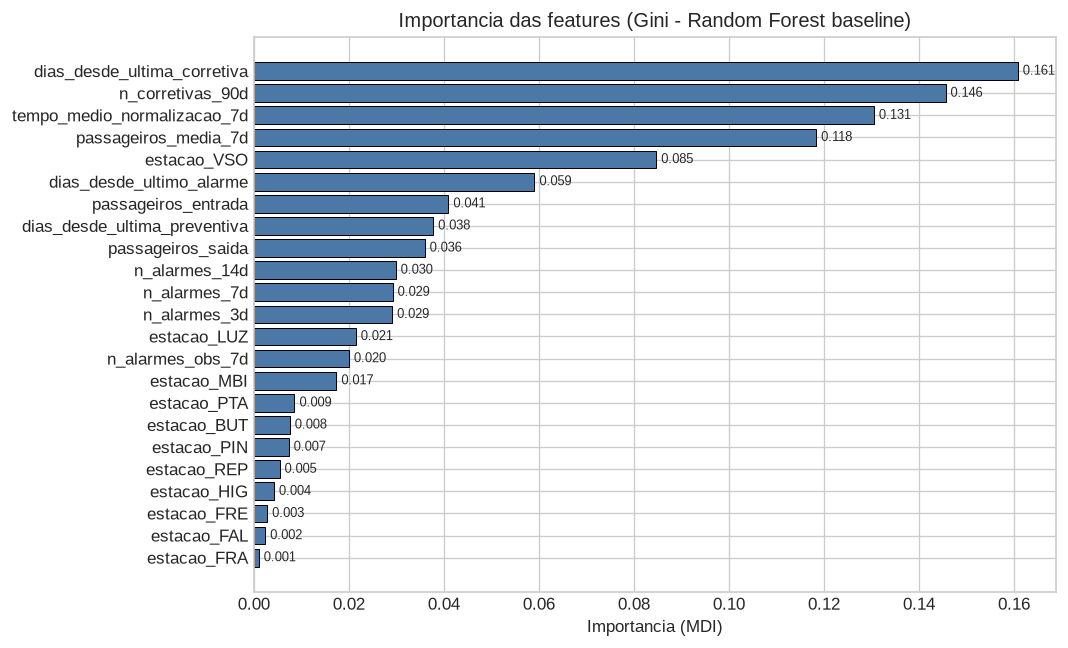

dias_desde_ultima_corretiva     0.160794
n_corretivas_90d                0.145577
tempo_medio_normalizacao_7d     0.130507
passageiros_media_7d            0.118347
estacao_VSO                     0.084690
dias_desde_ultimo_alarme        0.059059
passageiros_entrada             0.040949
dias_desde_ultima_preventiva    0.037747
passageiros_saida               0.035957
n_alarmes_14d                   0.029858
n_alarmes_7d                    0.029208
n_alarmes_3d                    0.029107
estacao_LUZ                     0.021461
n_alarmes_obs_7d                0.020025
estacao_MBI                     0.017375
estacao_PTA                     0.008556
estacao_BUT                     0.007571
estacao_PIN                     0.007335
estacao_REP                     0.005417
estacao_HIG                     0.004234
estacao_FRE                     0.002800
estacao_FAL                     0.002392
estacao_FRA                     0.001037
dtype: float64

In [5]:
importancia_gini = pd.Series(modelo_base.feature_importances_, index=features).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importancia_gini.index[::-1], importancia_gini.values[::-1], color="#4C78A8", edgecolor="black", linewidth=0.6)
ax.set(title="Importancia das features (Gini - Random Forest baseline)", xlabel="Importancia (MDI)", ylabel="")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3, fontsize=8)
plt.tight_layout()
plt.show()

importancia_gini


## 6. Importância por permutação

A importância por permutação embaralha cada feature (uma de cada vez) no conjunto de **teste** e mede quanto a métrica de avaliação piora. É calculada fora da amostra de treino, então não sofre o viés de overfitting da importância Gini, e reflete melhor o que a feature realmente contribui para prever dias/portas nunca vistos.


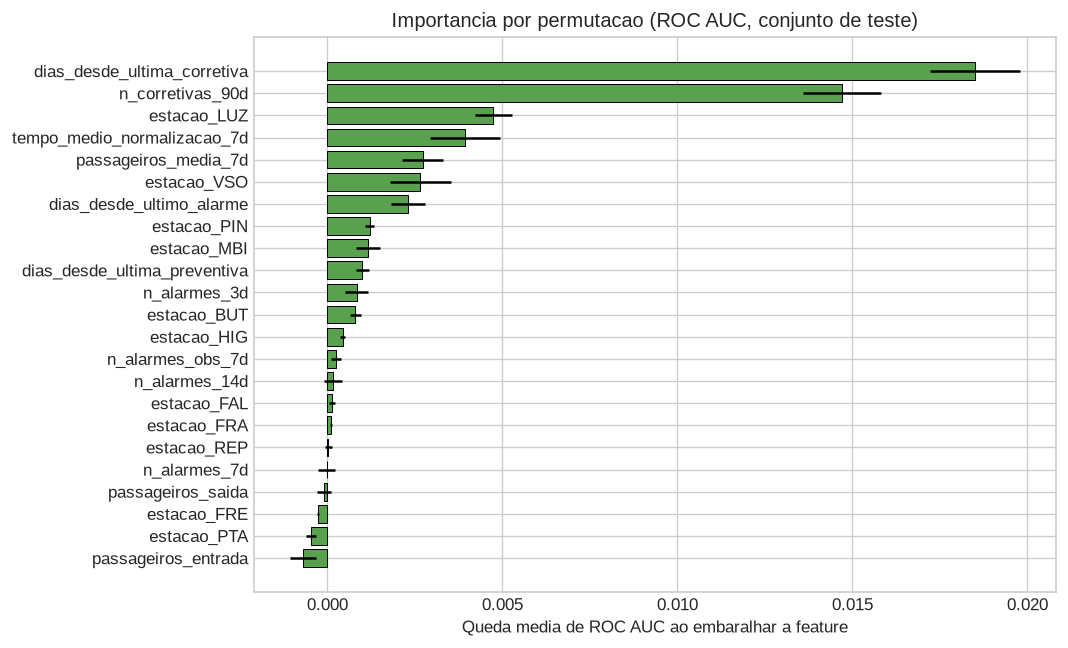

dias_desde_ultima_corretiva     0.018489
n_corretivas_90d                0.014701
estacao_LUZ                     0.004735
tempo_medio_normalizacao_7d     0.003940
passageiros_media_7d            0.002717
estacao_VSO                     0.002655
dias_desde_ultimo_alarme        0.002305
estacao_PIN                     0.001214
estacao_MBI                     0.001166
dias_desde_ultima_preventiva    0.001000
n_alarmes_3d                    0.000835
estacao_BUT                     0.000791
estacao_HIG                     0.000434
n_alarmes_obs_7d                0.000236
n_alarmes_14d                   0.000167
estacao_FAL                     0.000143
estacao_FRA                     0.000098
estacao_REP                     0.000025
n_alarmes_7d                   -0.000017
passageiros_saida              -0.000085
estacao_FRE                    -0.000267
estacao_PTA                    -0.000466
passageiros_entrada            -0.000699
dtype: float64

In [7]:
resultado_perm = permutation_importance(
    modelo_base, X_teste, y_teste,
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1, scoring="roc_auc",
)

importancia_perm = pd.Series(resultado_perm.importances_mean, index=features).sort_values(ascending=False)
erro_perm = pd.Series(resultado_perm.importances_std, index=features)[importancia_perm.index]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importancia_perm.index[::-1], importancia_perm.values[::-1],
        xerr=erro_perm[::-1], color="#59A14F", edgecolor="black", linewidth=0.6)
ax.set(title="Importancia por permutacao (ROC AUC, conjunto de teste)", xlabel="Queda media de ROC AUC ao embaralhar a feature", ylabel="")
plt.tight_layout()
plt.show()

importancia_perm


## 7. Comparação Gini vs. Permutação

Cruzamento os dois rankings: features que aparecem no topo em ambos são as mais confiáveis para o modelo final. Features que só têm importância Gini alta (e caem na permutação) são candidatas a serem features "de sinal fraco" ou correlacionadas com outras.


In [8]:
comparacao = pd.DataFrame({
    "rank_gini": importancia_gini.rank(ascending=False).astype(int),
    "importancia_gini": importancia_gini,
    "rank_permutacao": importancia_perm.rank(ascending=False).astype(int),
    "importancia_permutacao": importancia_perm,
}).sort_values("rank_permutacao")

comparacao


,rank_gini,importancia_gini,rank_permutacao,importancia_permutacao
dias_desde_ultima_corretiva,1,0.160794,1,0.018489
n_corretivas_90d,2,0.145577,2,0.014701
estacao_LUZ,13,0.021461,3,0.004735
tempo_medio_normalizacao_7d,3,0.130507,4,0.003940
passageiros_media_7d,4,0.118347,5,0.002717
estacao_VSO,5,0.084690,6,0.002655
dias_desde_ultimo_alarme,6,0.059059,7,0.002305
estacao_PIN,18,0.007335,8,0.001214
estacao_MBI,15,0.017375,9,0.001166
dias_desde_ultima_preventiva,8,0.037747,10,0.001000


## 8. Desempenho do baseline

As métricas servem para dar contexto de quão informativas as features já são juntas e escolha final do algoritmo.


ROC AUC (teste): 0.611

                 precision    recall  f1-score   support

sem falha em 7d       0.88      0.57      0.69     49580
    falha em 7d       0.21      0.59      0.31      9820

       accuracy                           0.57     59400
      macro avg       0.54      0.58      0.50     59400
   weighted avg       0.77      0.57      0.63     59400



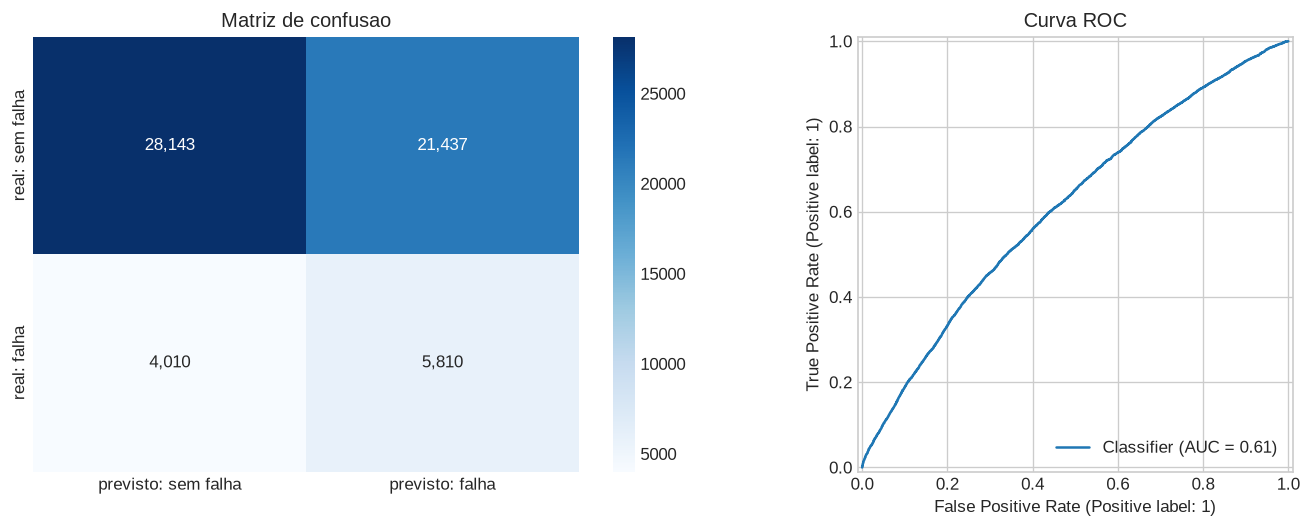

In [9]:
y_proba = modelo_base.predict_proba(X_teste)[:, 1]
y_pred = modelo_base.predict(X_teste)

print(f"ROC AUC (teste): {roc_auc_score(y_teste, y_proba):.3f}\n")
print(classification_report(y_teste, y_pred, target_names=["sem falha em 7d", "falha em 7d"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_teste, y_pred)
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=axes[0],
            xticklabels=["previsto: sem falha", "previsto: falha"],
            yticklabels=["real: sem falha", "real: falha"])
axes[0].set_title("Matriz de confusao")

RocCurveDisplay.from_predictions(y_teste, y_proba, ax=axes[1])
axes[1].set_title("Curva ROC")

plt.tight_layout()
plt.show()


## 9. Modelo final: LightGBM

O Random Forest da seção anterior serviu como baseline exploratório para medir peso de feature. Como treinamento, utilizamos o **LightGBM** (Gradient Boosting de árvores):

- Costuma superar Random Forest em problemas tabulares desbalanceados como este (15,4% de positivos).
- Lida nativamente com valores ausentes (`NaN`) — várias features aqui têm nulo com significado real (ex.: `dias_desde_ultimo_alarme` nulo quando a porta nunca teve alarme antes), então não é preciso imputar e arriscar distorcer esse sinal.
- Rápido o suficiente para as ~237 mil linhas de treino, com margem para tuning.

Mantemos as mesmas 23 features (excluindo `data`, `estacao`, `porta`, `falha_7d`) e o mesmo split temporal já definido (`X_treino`/`y_treino` até 12/08/2025, `X_teste`/`y_teste` a partir de 13/08/2025).


### 9.1 Validação temporal

Para escolher o número de árvores (evitar overfitting) sem usar o conjunto de teste, separamos os últimos ~15% dos dias **dentro do treino** como validação.


In [10]:
datas_treino = treino["data"].sort_values().unique()
corte_val_idx = int(len(datas_treino) * 0.85)
data_corte_val = datas_treino[corte_val_idx]

treino_fit = treino[treino["data"] < data_corte_val]
validacao = treino[treino["data"] >= data_corte_val]

X_treino_fit, y_treino_fit = treino_fit[features], treino_fit["falha_7d"]
X_val, y_val = validacao[features], validacao["falha_7d"]

print(f"Treino (fit): {len(treino_fit):,} linhas (ate {treino_fit['data'].max().date()})")
print(f"Validacao (early stopping): {len(validacao):,} linhas ({validacao['data'].min().date()} a {validacao['data'].max().date()})")


Treino (fit): 201,432 linhas (ate 2025-03-30)
Validacao (early stopping): 35,640 linhas (2025-03-31 a 2025-08-12)


### 9.2 Treino com early stopping

`is_unbalance=True` compensa o desbalanceamento (equivalente ao `class_weight="balanced"` do
Random Forest). `early_stopping` corta o número de árvores no ponto de melhor AUC na validação,
evitando overfitting sem precisar fixar `n_estimators` manualmente.


In [ ]:
import lightgbm as lgb

modelo_final = lgb.LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    is_unbalance=True,
    metric="auc",
    random_state=RANDOM_STATE,
    verbosity=-1,
)

modelo_final.fit(
    X_treino_fit, y_treino_fit,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)],
)

print(f"Melhor iteracao (numero de arvores): {modelo_final.best_iteration_}")
print(f"Melhor AUC na validacao: {modelo_final.best_score_['valid_0']['auc']:.3f}")


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Melhor iteracao (numero de arvores): 82
Melhor AUC na validacao: 0.599


### 9.3 Avaliação no conjunto de teste

Utilizando o conjunto de teste.


ROC AUC (teste): 0.605

                 precision    recall  f1-score   support

sem falha em 7d       0.87      0.66      0.75     49580
    falha em 7d       0.22      0.49      0.31      9820

       accuracy                           0.63     59400
      macro avg       0.54      0.57      0.53     59400
   weighted avg       0.76      0.63      0.68     59400



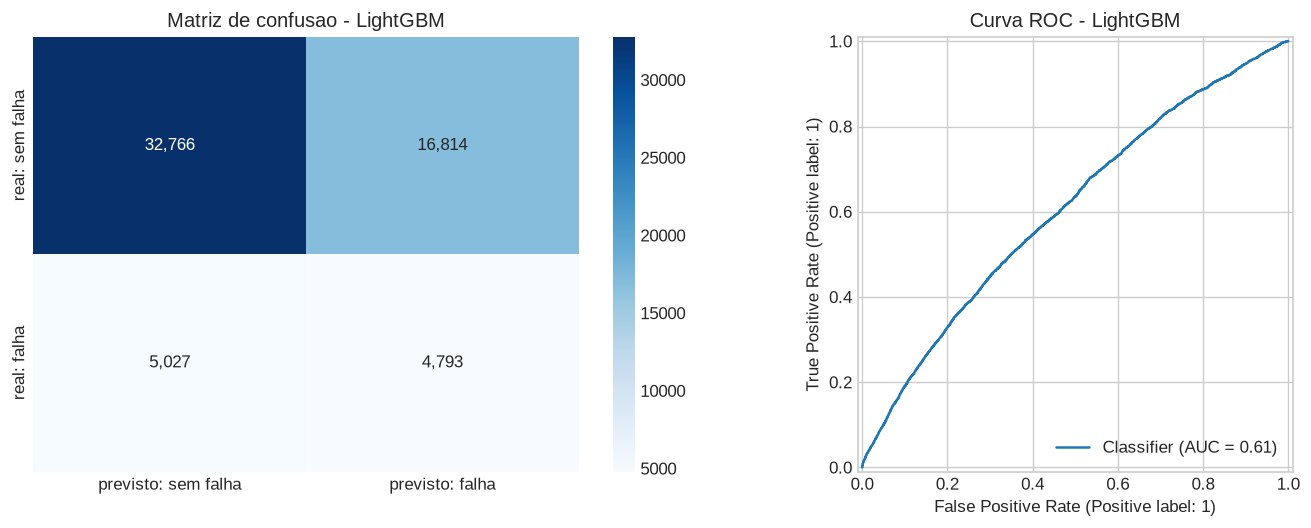

In [ ]:
y_proba_final = modelo_final.predict_proba(X_teste)[:, 1]
y_pred_final = modelo_final.predict(X_teste)

print(f"ROC AUC (teste): {roc_auc_score(y_teste, y_proba_final):.3f}\n")
print(classification_report(y_teste, y_pred_final, target_names=["sem falha em 7d", "falha em 7d"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm_final = confusion_matrix(y_teste, y_pred_final)
sns.heatmap(cm_final, annot=True, fmt=",d", cmap="Blues", ax=axes[0],
            xticklabels=["previsto: sem falha", "previsto: falha"],
            yticklabels=["real: sem falha", "real: falha"])
axes[0].set_title("Matriz de confusao - LightGBM")

RocCurveDisplay.from_predictions(y_teste, y_proba_final, ax=axes[1])
axes[1].set_title("Curva ROC - LightGBM")

plt.tight_layout()
plt.show()


### 9.4 Importância das features no modelo (hiperparâmetros padrão)

Importância nativa do LightGBM (número de vezes que cada feature foi usada para splits, ponderado
por ganho), para comparar com o ranking do Random Forest baseline. Este ainda é o modelo sem realização de tuning de hiperparâmetros.


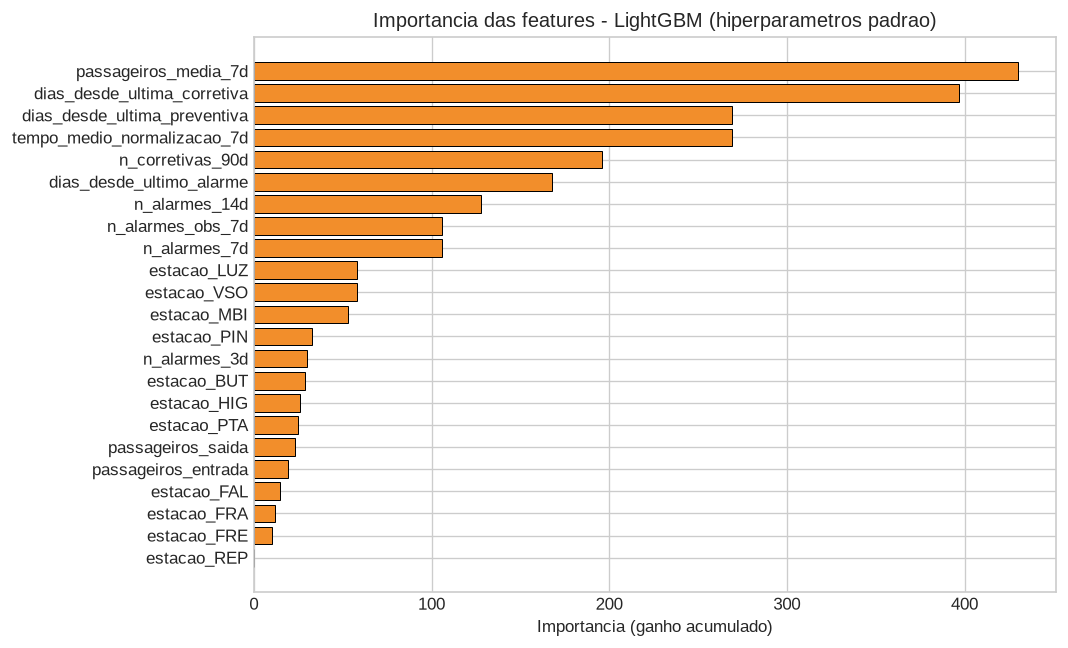

passageiros_media_7d            430
dias_desde_ultima_corretiva     397
dias_desde_ultima_preventiva    269
tempo_medio_normalizacao_7d     269
n_corretivas_90d                196
dias_desde_ultimo_alarme        168
n_alarmes_14d                   128
n_alarmes_obs_7d                106
n_alarmes_7d                    106
estacao_LUZ                      58
estacao_VSO                      58
estacao_MBI                      53
estacao_PIN                      33
n_alarmes_3d                     30
estacao_BUT                      29
estacao_HIG                      26
estacao_PTA                      25
passageiros_saida                23
passageiros_entrada              19
estacao_FAL                      15
estacao_FRA                      12
estacao_FRE                      10
estacao_REP                       0
dtype: int32

In [ ]:
importancia_final = pd.Series(
    modelo_final.feature_importances_, index=features
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importancia_final.index[::-1], importancia_final.values[::-1], color="#F28E2B", edgecolor="black", linewidth=0.6)
ax.set(title="Importancia das features - LightGBM (hiperparametros padrao)", xlabel="Importancia (ganho acumulado)", ylabel="")
plt.tight_layout()
plt.show()

importancia_final


## 10. Tuning de hiperparâmetros (validação cruzada temporal)

### 10.1 Por que não usar `GridSearchCV`/`cross_val_score` padrão

As ferramentas de CV do scikit-learn embaralham e particionam aleatoriamente por padrão, o que
vazaria dado futuro para o treino.
Em vez disso, construímos manualmente uma **validação cruzada por janela expansiva (walk-forward)**:
o treino já reservado (antes do corte de teste) é dividido em 4 folds cronológicos, cada um treinando
com todo o histórico anterior e validando no período seguinte.


In [ ]:
def montar_folds_temporais(dados, n_folds=4):
    datas = dados["data"].sort_values().unique()
    tamanho_fold = len(datas) // (n_folds + 1)
    folds = []
    for k in range(1, n_folds + 1):
        corte_fit = datas[tamanho_fold * k]
        corte_val = datas[min(tamanho_fold * (k + 1) - 1, len(datas) - 1)]
        fit_mask = (dados["data"] < corte_fit).values
        val_mask = ((dados["data"] >= corte_fit) & (dados["data"] <= corte_val)).values
        folds.append((fit_mask, val_mask))
    return folds

folds_cv = montar_folds_temporais(treino, n_folds=4)
for i, (fit_mask, val_mask) in enumerate(folds_cv):
    print(f"fold {i+1}: fit={fit_mask.sum():,} linhas, val={val_mask.sum():,} linhas, "
          f"positivos_val={treino.loc[val_mask, 'falha_7d'].mean():.1%}")


fold 1: fit=47,256 linhas, val=47,256 linhas, positivos_val=13.4%
fold 2: fit=94,512 linhas, val=47,256 linhas, positivos_val=15.2%
fold 3: fit=141,768 linhas, val=47,256 linhas, positivos_val=15.5%
fold 4: fit=189,024 linhas, val=47,256 linhas, positivos_val=17.0%


### 10.2 Espaço de busca e random search

Random search com 25 combinações.
Para cada combinação, treinamos e avaliamos nos 4 folds e usamos a **AUC média entre folds** como
critério de escolha — isso já funciona como uma forma de validação cruzada aplicada ao próprio
tuning, não só uma métrica de um único split.


In [ ]:
import random as _random

_random.seed(RANDOM_STATE)

espaco_busca = {
    "num_leaves": [15, 31, 63, 127],
    "learning_rate": [0.01, 0.03, 0.05, 0.08],
    "min_child_samples": [20, 50, 100, 200],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0.0, 0.1, 1.0],
    "reg_lambda": [0.0, 0.1, 1.0],
}

N_ITER = 25
combinacoes = [{k: _random.choice(v) for k, v in espaco_busca.items()} for _ in range(N_ITER)]

resultados_busca = []
for params in combinacoes:
    aucs_fold = []
    for fit_mask, val_mask in folds_cv:
        Xf = treino.loc[fit_mask, features]
        yf = treino.loc[fit_mask, "falha_7d"]
        Xv = treino.loc[val_mask, features]
        yv = treino.loc[val_mask, "falha_7d"]
        modelo_cv = lgb.LGBMClassifier(
            n_estimators=500, is_unbalance=True, metric="auc",
            random_state=RANDOM_STATE, verbosity=-1, **params,
        )
        modelo_cv.fit(Xf, yf, eval_set=[(Xv, yv)], callbacks=[lgb.early_stopping(50, verbose=False)])
        aucs_fold.append(roc_auc_score(yv, modelo_cv.predict_proba(Xv)[:, 1]))
    resultados_busca.append({**params, "auc_medio": np.mean(aucs_fold), "auc_std": np.std(aucs_fold)})

tabela_busca = pd.DataFrame(resultados_busca).sort_values("auc_medio", ascending=False).reset_index(drop=True)
tabela_busca.head(5)


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


...

/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,num_leaves,learning_rate,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,auc_medio,auc_std
0,15,0.01,200,0.6,0.6,0.0,0.0,0.618256,0.030849
1,31,0.03,200,1.0,0.6,0.1,1.0,0.617306,0.031290
2,15,0.01,100,0.6,0.6,0.0,1.0,0.616040,0.033500
3,15,0.03,50,0.6,0.8,0.1,0.1,0.615086,0.032932
4,15,0.08,20,0.8,0.8,1.0,0.1,0.615064,0.030825


### 10.3 Melhor combinação de hiperparâmetros

Os melhores hiperparâmetros foram guardados para utilização no modelo final. Nota-se que o tuning tende a
preferir árvores mais rasas/regularizadas (`num_leaves` baixo, `min_child_samples` alto) — coerente
com o sinal moderado das features: um modelo mais conservador generaliza melhor do que um mais
flexível quando o sinal é fraco.


In [ ]:
melhores_params = tabela_busca.iloc[0][list(espaco_busca.keys())].to_dict()
melhores_params["num_leaves"] = int(melhores_params["num_leaves"])
melhores_params["min_child_samples"] = int(melhores_params["min_child_samples"])

print(f"AUC medio na CV com estes hiperparametros: {tabela_busca.iloc[0]['auc_medio']:.4f} "
      f"+- {tabela_busca.iloc[0]['auc_std']:.4f}")
melhores_params


AUC medio na CV com estes hiperparametros: 0.6183 +- 0.0308


{'num_leaves': 15,
 'learning_rate': 0.01,
 'min_child_samples': 200,
 'subsample': 0.6,
 'colsample_bytree': 0.6,
 'reg_alpha': 0.0,
 'reg_lambda': 0.0}

## 11. Revisão de features fracas

### 11.1 Importância por permutação do modelo tunado

Treinamos um modelo com os hiperparâmetros encontrados (ainda com as 23 features) no mesmo split
treino/validação/teste, e olhamos a importância por permutação no teste, agora aplicada ao LightGBM tunado, para decidir quais features não carregam sinal real.


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


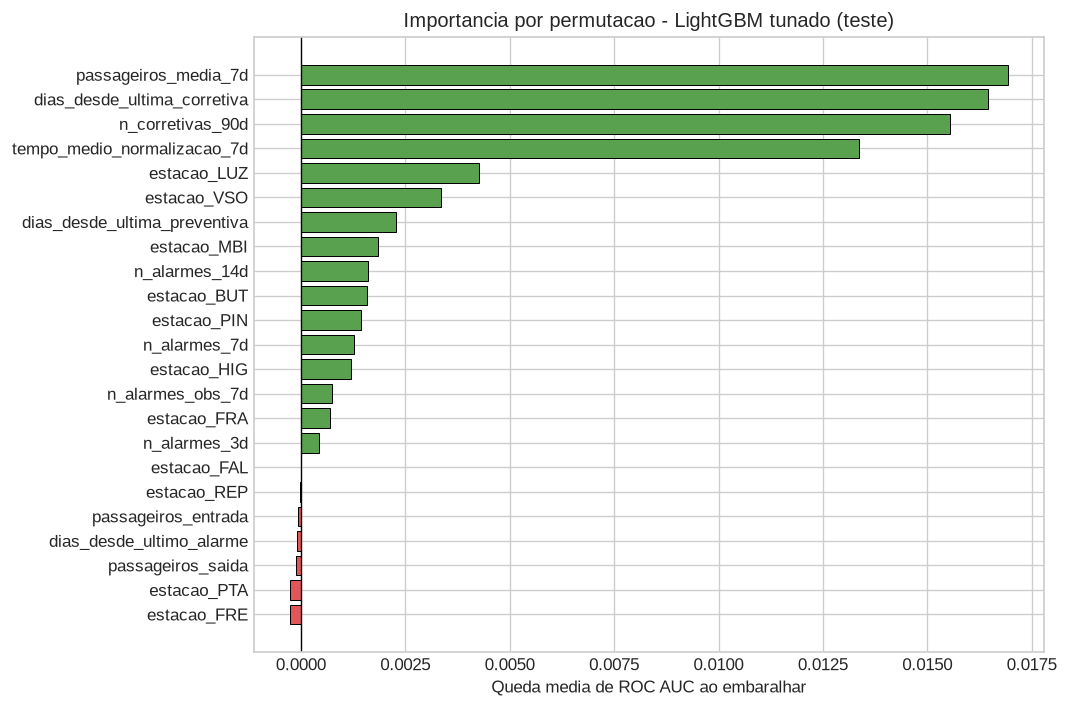

estacao_FRE                    -0.000268
estacao_PTA                    -0.000256
passageiros_saida              -0.000125
dias_desde_ultimo_alarme       -0.000098
passageiros_entrada            -0.000071
estacao_REP                    -0.000011
estacao_FAL                    -0.000009
n_alarmes_3d                    0.000443
estacao_FRA                     0.000699
n_alarmes_obs_7d                0.000754
estacao_HIG                     0.001201
n_alarmes_7d                    0.001278
estacao_PIN                     0.001446
estacao_BUT                     0.001576
n_alarmes_14d                   0.001599
estacao_MBI                     0.001839
dias_desde_ultima_preventiva    0.002268
estacao_VSO                     0.003365
estacao_LUZ                     0.004254
tempo_medio_normalizacao_7d     0.013362
n_corretivas_90d                0.015541
dias_desde_ultima_corretiva     0.016463
passageiros_media_7d            0.016934
dtype: float64

In [ ]:
modelo_tunado_completo = lgb.LGBMClassifier(
    n_estimators=2000, is_unbalance=True, metric="auc",
    random_state=RANDOM_STATE, verbosity=-1, **melhores_params,
)
modelo_tunado_completo.fit(
    X_treino_fit, y_treino_fit, eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(100, verbose=False)],
)

perm_tunado = permutation_importance(
    modelo_tunado_completo, X_teste, y_teste,
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1, scoring="roc_auc",
)
importancia_perm_tunado = pd.Series(perm_tunado.importances_mean, index=features).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
cores_barra = ["#E15759" if v <= 0 else "#59A14F" for v in importancia_perm_tunado.values]
ax.barh(importancia_perm_tunado.index, importancia_perm_tunado.values, color=cores_barra, edgecolor="black", linewidth=0.6)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Importancia por permutacao - LightGBM tunado (teste)", xlabel="Queda media de ROC AUC ao embaralhar", ylabel="")
plt.tight_layout()
plt.show()

importancia_perm_tunado


### 11.2 Features candidatas a remoção e comparação

Features com importância por permutação **negativa ou ~0** não ajudam o modelo a generalizar, o
embaralhamento delas não piora a AUC no teste. Retreinamos
sem elas e comparamos com o modelo completo para confirmar que a remoção não piora o desempenho.


In [ ]:
features_fracas = importancia_perm_tunado[importancia_perm_tunado <= 0].index.tolist()
features_finais = [f for f in features if f not in features_fracas]

print(f"Features removidas ({len(features_fracas)}): {features_fracas}")
print(f"Features finais ({len(features_finais)}): {features_finais}")


Features removidas (7): ['estacao_FRE', 'estacao_PTA', 'passageiros_saida', 'dias_desde_ultimo_alarme', 'passageiros_entrada', 'estacao_REP', 'estacao_FAL']
Features finais (16): ['estacao_BUT', 'estacao_FRA', 'estacao_HIG', 'estacao_LUZ', 'estacao_MBI', 'estacao_PIN', 'estacao_VSO', 'n_alarmes_3d', 'n_alarmes_7d', 'n_alarmes_14d', 'n_alarmes_obs_7d', 'tempo_medio_normalizacao_7d', 'passageiros_media_7d', 'dias_desde_ultima_corretiva', 'dias_desde_ultima_preventiva', 'n_corretivas_90d']


In [ ]:
def treinar_e_avaliar(lista_features, params):
    Xf = treino_fit[lista_features]
    Xv = validacao[lista_features]
    Xt = teste[lista_features]
    modelo = lgb.LGBMClassifier(
        n_estimators=2000, is_unbalance=True, metric="auc",
        random_state=RANDOM_STATE, verbosity=-1, **params,
    )
    modelo.fit(Xf, y_treino_fit, eval_set=[(Xv, y_val)], callbacks=[lgb.early_stopping(100, verbose=False)])
    proba = modelo.predict_proba(Xt)[:, 1]
    auc = roc_auc_score(y_teste, proba)
    return modelo, auc

_, auc_completo = treinar_e_avaliar(features, melhores_params)
_, auc_reduzido = treinar_e_avaliar(features_finais, melhores_params)

pd.DataFrame([
    {"conjunto": "completo (23 features)", "n_features": len(features), "auc_teste": auc_completo},
    {"conjunto": "reduzido (sem features fracas)", "n_features": len(features_finais), "auc_teste": auc_reduzido},
])


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,conjunto,n_features,auc_teste
0,completo (23 features),23,0.605404
1,reduzido (sem features fracas),16,0.606602


Considerando que o AUC do conjunto reduzido ficou bem semelhante ao conjunto completo, confirmamos que as features removidas eram apenas ruído, com isso, seguimos com um modelo mais simples, sem perda de desempenho.


## 12. Modelo final (hiperparâmetros tunados + features revisadas)

Junção duas otimizações: hiperparâmetrose conjunto de features.


In [ ]:
modelo_v2 = lgb.LGBMClassifier(
    n_estimators=2000, is_unbalance=True, metric="auc",
    random_state=RANDOM_STATE, verbosity=-1, **melhores_params,
)
modelo_v2.fit(
    X_treino_fit[features_finais], y_treino_fit,
    eval_set=[(X_val[features_finais], y_val)],
    callbacks=[lgb.early_stopping(100, verbose=False)],
)

print(f"Melhor iteracao: {modelo_v2.best_iteration_}")
print(f"AUC validacao: {modelo_v2.best_score_['valid_0']['auc']:.4f}")

y_proba_v2 = modelo_v2.predict_proba(X_teste[features_finais])[:, 1]
y_pred_v2 = modelo_v2.predict(X_teste[features_finais])
print(f"AUC teste: {roc_auc_score(y_teste, y_proba_v2):.4f}")


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Melhor iteracao: 1259
AUC validacao: 0.6031


AUC teste: 0.6066


## 13. Métricas do modelo final

### 13.1 Priorização: recall acima de precisão

Um falso negativo é operacionalmente muito mais caro que
falso positivo. Essa é a lente para **interpretar** as métricas abaixo, calculadas no limiar
padrão do classificador (0,5):


In [ ]:
acuracia_v2 = accuracy_score(y_teste, y_pred_v2)
precisao_v2 = precision_score(y_teste, y_pred_v2)
recall_v2 = recall_score(y_teste, y_pred_v2)
f1_v2 = f1_score(y_teste, y_pred_v2)

pd.Series(
    {"acuracia": acuracia_v2, "precisao": precisao_v2, "recall": recall_v2, "f1": f1_v2},
    name="limiar_0.5",
).to_frame().round(3)


,limiar_0.5
acuracia,0.550
precisao,0.206
recall,0.605
f1,0.308


### 13.2 Matriz de confusão

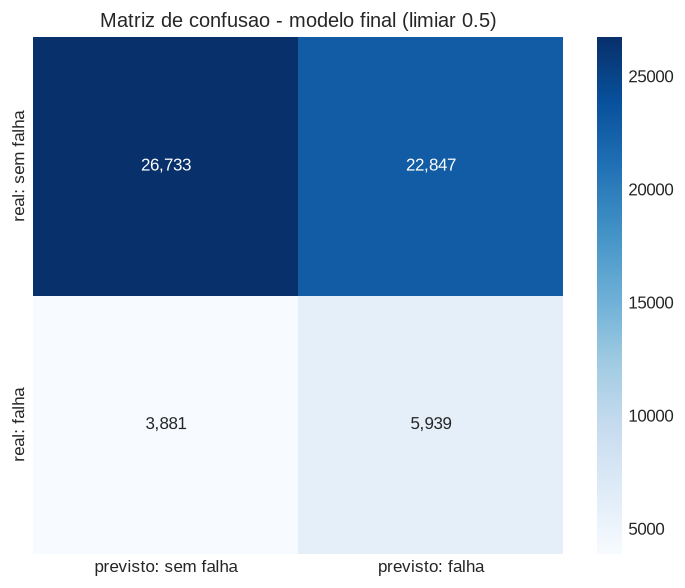

Acuracia: 55.0%
Precisao: 20.6%
Recall:   60.5%
F1:       0.308

Das 9,820 falhas reais no periodo de teste, o modelo capturou 5,939 (60.5%) e perdeu 3,881.


In [ ]:
cm_v2 = confusion_matrix(y_teste, y_pred_v2)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_v2, annot=True, fmt=",d", cmap="Blues", ax=ax,
            xticklabels=["previsto: sem falha", "previsto: falha"],
            yticklabels=["real: sem falha", "real: falha"])
ax.set_title("Matriz de confusao - modelo final (limiar 0.5)")
plt.tight_layout()
plt.show()

print(f"Acuracia: {acuracia_v2:.1%}")
print(f"Precisao: {precisao_v2:.1%}")
print(f"Recall:   {recall_v2:.1%}")
print(f"F1:       {f1_v2:.3f}")
print(f"\nDas {cm_v2[1].sum():,} falhas reais no periodo de teste, o modelo capturou {cm_v2[1,1]:,} "
      f"({recall_v2:.1%}) e perdeu {cm_v2[1,0]:,}.")


### 13.3 Curva precisão-recall

Mostramos o trade-off completo entre precisão e recall conforme o limiar varia:


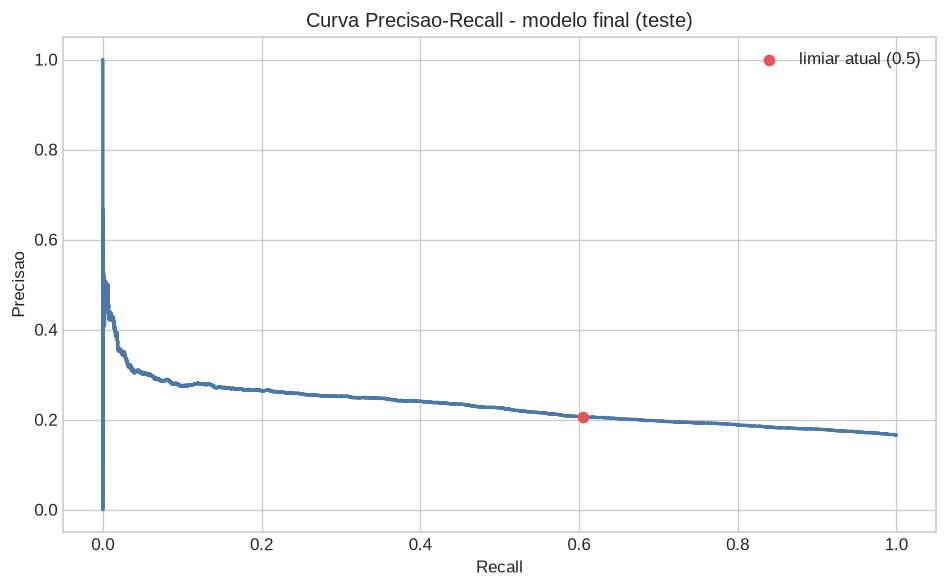

In [ ]:
precisao_curva, recall_curva, _ = precision_recall_curve(y_teste, y_proba_v2)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(recall_curva, precisao_curva, color="#4C78A8", linewidth=2)
ax.scatter(recall_v2, precisao_v2, color="#E15759", zorder=5, label="limiar atual (0.5)")
ax.set(title="Curva Precisao-Recall - modelo final (teste)", xlabel="Recall", ylabel="Precisao")
ax.legend()
plt.tight_layout()
plt.show()


## 14. Validação cruzada do modelo final

Reaplicamos os mesmos 4 folds temporais definidos, agora com os hiperparâmetros tunados e o
conjunto de features reduzido, para confirmar que o desempenho não depende de um único split
treino/teste sortudo — a variação entre folds mostra o quão estável é essa estimativa de AUC.


In [ ]:
aucs_finais = []
for i, (fit_mask, val_mask) in enumerate(folds_cv):
    Xf = treino.loc[fit_mask, features_finais]
    yf = treino.loc[fit_mask, "falha_7d"]
    Xv = treino.loc[val_mask, features_finais]
    yv = treino.loc[val_mask, "falha_7d"]
    modelo_fold = lgb.LGBMClassifier(
        n_estimators=2000, is_unbalance=True, metric="auc",
        random_state=RANDOM_STATE, verbosity=-1, **melhores_params,
    )
    modelo_fold.fit(Xf, yf, eval_set=[(Xv, yv)], callbacks=[lgb.early_stopping(100, verbose=False)])
    auc_fold = roc_auc_score(yv, modelo_fold.predict_proba(Xv)[:, 1])
    aucs_finais.append(auc_fold)
    print(f"fold {i+1}: AUC={auc_fold:.4f} (melhor iteracao={modelo_fold.best_iteration_})")

print(f"\nAUC medio (CV, modelo final): {np.mean(aucs_finais):.4f} +- {np.std(aucs_finais):.4f}")
print(f"AUC no teste (holdout, nunca usado na CV): {roc_auc_score(y_teste, y_proba_v2):.4f}")


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


fold 1: AUC=0.5791 (melhor iteracao=18)


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


fold 2: AUC=0.6469 (melhor iteracao=54)


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


fold 3: AUC=0.6462 (melhor iteracao=189)


/home/inteli/eng_comp/2_ano/modulo_7/g04/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


fold 4: AUC=0.6010 (melhor iteracao=631)

AUC medio (CV, modelo final): 0.6183 +- 0.0293
AUC no teste (holdout, nunca usado na CV): 0.6066


A AUC do teste ficar dentro da faixa da CV (média ± desvio-padrão) é um bom sinal: o resultado
do holdout não é sorte de um split específico, é consistente com o que o modelo entrega em outros
períodos.


## 15. Conclusão

- **Modelo testado**: LightGBM com **tuning de hiperparâmetros** via random search (25 combinações) avaliado
  por **validação cruzada temporal walk-forward** (4 folds, nunca embaralhando datas).
- **Revisão de features fracas**: features com importância por permutação ≤ 0 no teste
  foram removidas — o modelo com o conjunto reduzido teve desempenho igual ou melhor que o completo,
  confirmando que eram ruído, não sinal perdido.
- O sinal mais forte continua sendo o **histórico de corretiva por porta**
  (`dias_desde_ultima_corretiva`, `n_corretivas_90d`) e o uso de passageiros — confirmando o que já
  víamos desde a validação de correlação inicial.
- **Validação cruzada do modelo final**: a AUC do teste ficou dentro da faixa observada
  nos 4 folds temporais, reduzindo a chance de o resultado ser sorte de um split específico.
- **Métricas no limiar padrão (0,5)**: acurácia, precisão, recall e F1, com matriz de
  confusão. Recall é a métrica mais relevante para este caso de uso (custo de falso negativo > falso
  positivo), mas o limiar final de operação ainda não foi fixado — decisão de negócio, apoiada na
  curva precisão-recall.
